In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files

uploaded = files.upload()

train = pd.read_csv("Bike_Sharing_Day58_Advanced_EDA.csv")

print("Dataset loaded successfully!")
print("Dataset Shape:", train.shape)

train.head()

Saving Bike_Sharing_Day58_Advanced_EDA.csv to Bike_Sharing_Day58_Advanced_EDA.csv
Dataset loaded successfully!
Dataset Shape: (10886, 21)


,datetime,season,holiday,workingday,weather,temp,atemp,humidity,windspeed,casual,...,count,year,month,day,hour,weekday,temp_group,humidity_group,windspeed_group,demand_level
0,2011-01-01 00:00:00,1,0,0,1,9.84,14.395,81,0.0,3,...,16,2011,1,1,0,5,0-10°C,80-100%,0-10,Low Demand
1,2011-01-01 01:00:00,1,0,0,1,9.02,13.635,80,0.0,8,...,40,2011,1,1,1,5,0-10°C,60-80%,0-10,Low Demand
2,2011-01-01 02:00:00,1,0,0,1,9.02,13.635,80,0.0,5,...,32,2011,1,1,2,5,0-10°C,60-80%,0-10,Low Demand
3,2011-01-01 03:00:00,1,0,0,1,9.84,14.395,75,0.0,3,...,13,2011,1,1,3,5,0-10°C,60-80%,0-10,Low Demand
4,2011-01-01 04:00:00,1,0,0,1,9.84,14.395,75,0.0,0,...,1,2011,1,1,4,5,0-10°C,60-80%,0-10,Low Demand


In [2]:
season_map = {
    1: "Spring",
    2: "Summer",
    3: "Fall",
    4: "Winter"
}

weather_map = {
    1: "Clear",
    2: "Mist / Cloudy",
    3: "Light Rain / Snow",
    4: "Heavy Rain / Snow"
}

weekday_map = {
    0: "Monday",
    1: "Tuesday",
    2: "Wednesday",
    3: "Thursday",
    4: "Friday",
    5: "Saturday",
    6: "Sunday"
}

train["season_name"] = train["season"].map(season_map)
train["weather_name"] = train["weather"].map(weather_map)
train["weekday_name"] = train["weekday"].map(weekday_map)

print("Dashboard labels created successfully!")

train[["season", "season_name",
       "weather", "weather_name",
       "weekday", "weekday_name"]].head()

Dashboard labels created successfully!


,season,season_name,weather,weather_name,weekday,weekday_name
0,1,Spring,1,Clear,5,Saturday
1,1,Spring,1,Clear,5,Saturday
2,1,Spring,1,Clear,5,Saturday
3,1,Spring,1,Clear,5,Saturday
4,1,Spring,1,Clear,5,Saturday


In [3]:
total_rentals = train["count"].sum()
average_rentals = train["count"].mean()
casual_rentals = train["casual"].sum()
registered_rentals = train["registered"].sum()

registered_percentage = (
    registered_rentals / total_rentals
) * 100

print("BIKE SHARING DASHBOARD — KEY METRICS")
print("-" * 45)
print(f"Total Rentals: {total_rentals:,}")
print(f"Average Hourly Rentals: {average_rentals:.2f}")
print(f"Casual Rentals: {casual_rentals:,}")
print(f"Registered Rentals: {registered_rentals:,}")
print(f"Registered User Contribution: {registered_percentage:.2f}%")

BIKE SHARING DASHBOARD — KEY METRICS
---------------------------------------------
Total Rentals: 2,085,476
Average Hourly Rentals: 191.57
Casual Rentals: 392,135
Registered Rentals: 1,693,341
Registered User Contribution: 81.20%


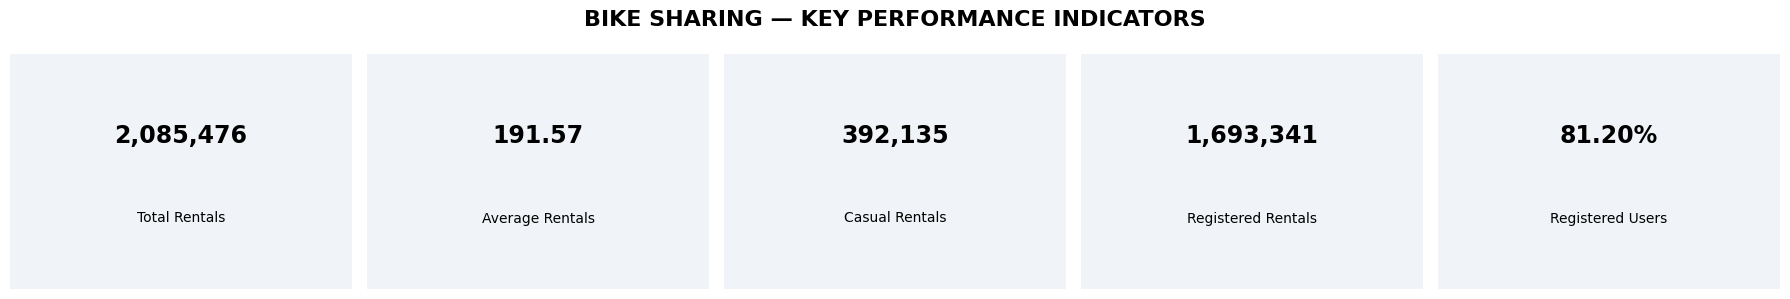

In [4]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 5, figsize=(18, 3))

kpis = [
    ("Total Rentals", f"{total_rentals:,}"),
    ("Average Rentals", f"{average_rentals:.2f}"),
    ("Casual Rentals", f"{casual_rentals:,}"),
    ("Registered Rentals", f"{registered_rentals:,}"),
    ("Registered Users", f"{registered_percentage:.2f}%")
]

for ax, (title, value) in zip(axes, kpis):
    ax.text(0.5, 0.65, value,
            ha="center", va="center",
            fontsize=17, fontweight="bold")

    ax.text(0.5, 0.30, title,
            ha="center", va="center",
            fontsize=10)

    ax.set_facecolor("#F0F4F8")
    ax.set_xticks([])
    ax.set_yticks([])

    for spine in ax.spines.values():
        spine.set_visible(False)

fig.suptitle(
    "BIKE SHARING — KEY PERFORMANCE INDICATORS",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

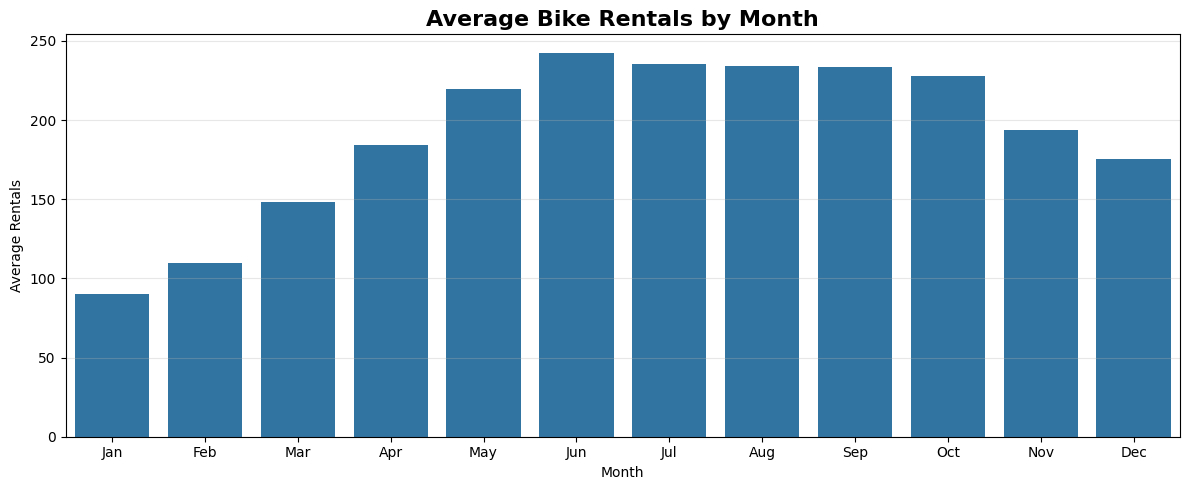

In [5]:
import seaborn as sns
import matplotlib.pyplot as plt

monthly_demand = (
    train.groupby("month")["count"]
    .mean()
    .reset_index()
)

plt.figure(figsize=(12, 5))

sns.barplot(
    data=monthly_demand,
    x="month",
    y="count"
)

plt.title("Average Bike Rentals by Month",
          fontsize=16, fontweight="bold")

plt.xlabel("Month")
plt.ylabel("Average Rentals")

plt.xticks(
    ticks=range(12),
    labels=["Jan", "Feb", "Mar", "Apr", "May", "Jun",
            "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
)

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

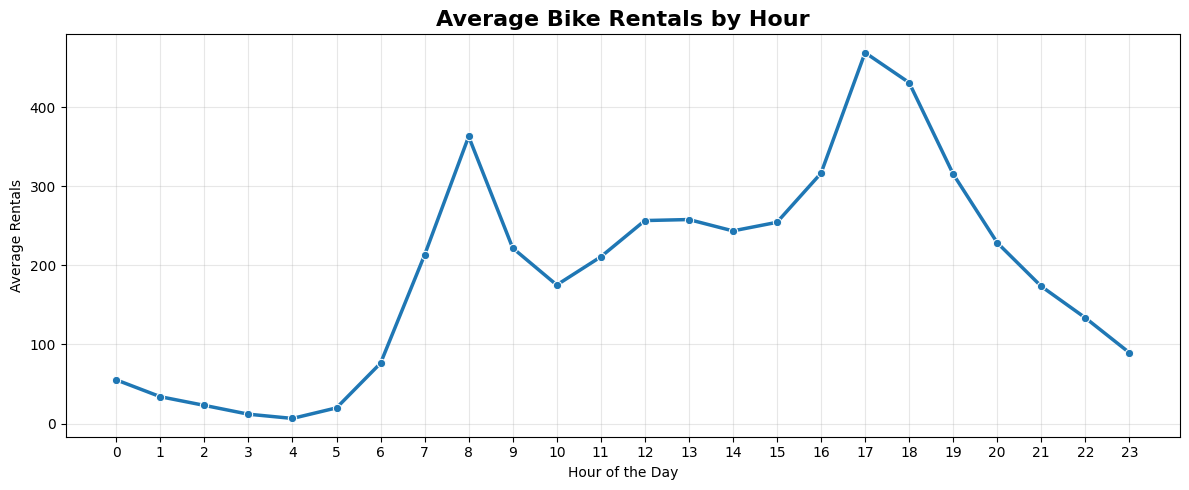

In [6]:
hourly_demand = (
    train.groupby("hour")["count"]
    .mean()
    .reset_index()
)

plt.figure(figsize=(12, 5))

sns.lineplot(
    data=hourly_demand,
    x="hour",
    y="count",
    marker="o",
    linewidth=2.5
)

plt.title("Average Bike Rentals by Hour",
          fontsize=16, fontweight="bold")

plt.xlabel("Hour of the Day")
plt.ylabel("Average Rentals")

plt.xticks(range(0, 24))
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

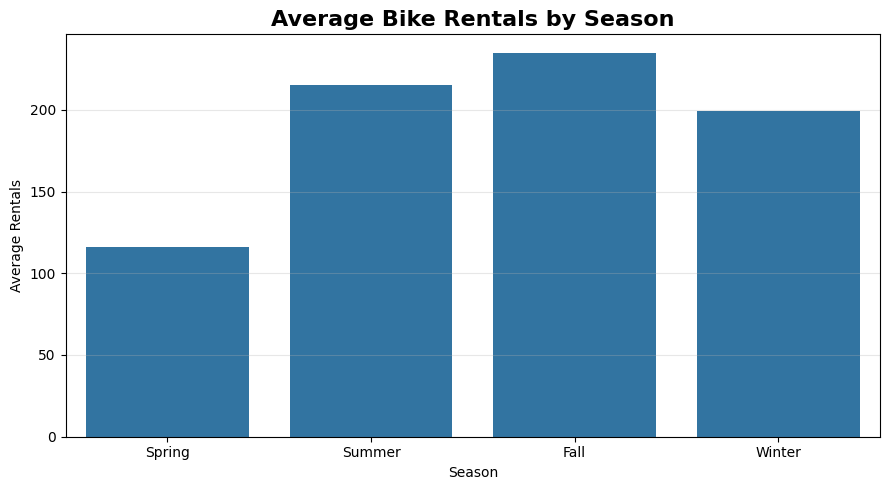

In [7]:
season_demand = (
    train.groupby("season_name")["count"]
    .mean()
    .reindex(["Spring", "Summer", "Fall", "Winter"])
    .reset_index()
)

plt.figure(figsize=(9, 5))

sns.barplot(
    data=season_demand,
    x="season_name",
    y="count"
)

plt.title("Average Bike Rentals by Season",
          fontsize=16, fontweight="bold")

plt.xlabel("Season")
plt.ylabel("Average Rentals")

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

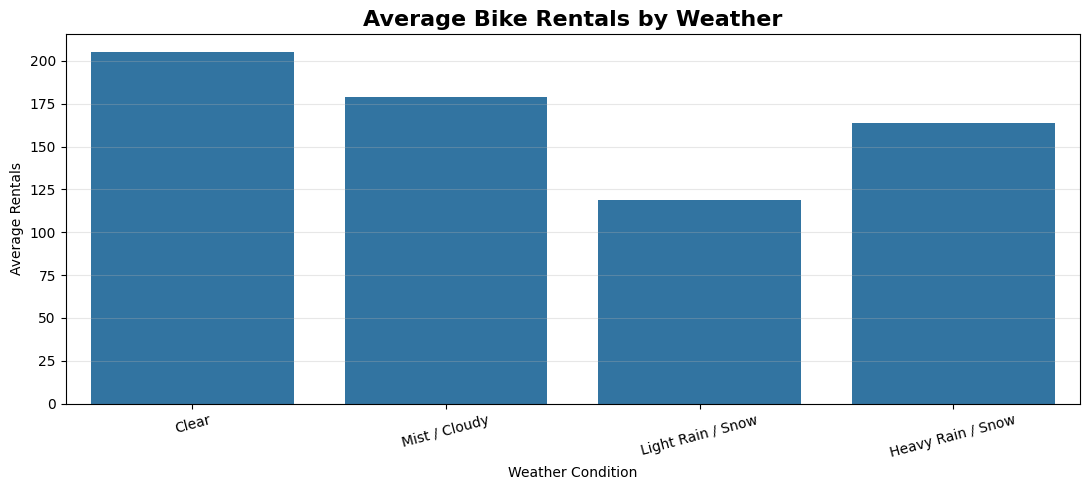

In [8]:
weather_demand = (
    train.groupby("weather_name")["count"]
    .mean()
    .reindex([
        "Clear",
        "Mist / Cloudy",
        "Light Rain / Snow",
        "Heavy Rain / Snow"
    ])
    .reset_index()
)

plt.figure(figsize=(11, 5))

sns.barplot(
    data=weather_demand,
    x="weather_name",
    y="count"
)

plt.title("Average Bike Rentals by Weather",
          fontsize=16, fontweight="bold")

plt.xlabel("Weather Condition")
plt.ylabel("Average Rentals")

plt.xticks(rotation=15)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

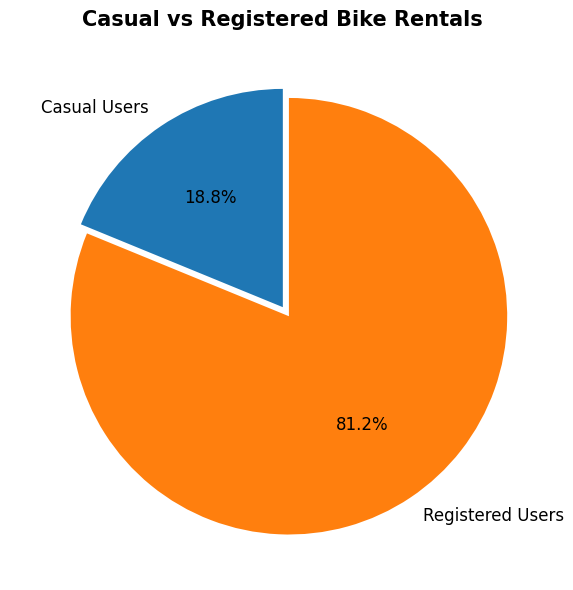

In [9]:
user_type_data = [
    casual_rentals,
    registered_rentals
]

user_labels = ["Casual Users", "Registered Users"]

plt.figure(figsize=(8, 6))

plt.pie(
    user_type_data,
    labels=user_labels,
    autopct="%1.1f%%",
    startangle=90,
    explode=(0, 0.05),
    textprops={"fontsize": 12}
)

plt.title(
    "Casual vs Registered Bike Rentals",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

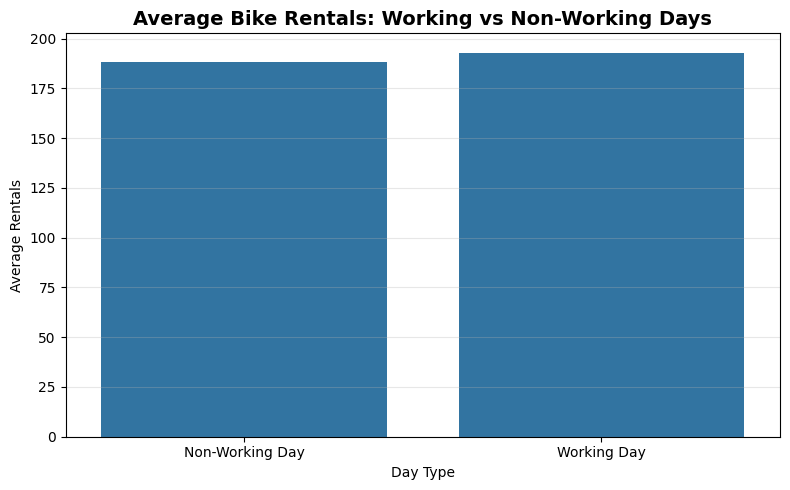

,workingday,count,day_type
0,0,188.506621,Non-Working Day
1,1,193.011873,Working Day


In [10]:
working_demand = (
    train.groupby("workingday")["count"]
    .mean()
    .reset_index()
)

working_demand["day_type"] = working_demand["workingday"].map({
    0: "Non-Working Day",
    1: "Working Day"
})

plt.figure(figsize=(8, 5))

sns.barplot(
    data=working_demand,
    x="day_type",
    y="count"
)

plt.title(
    "Average Bike Rentals: Working vs Non-Working Days",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Day Type")
plt.ylabel("Average Rentals")

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

working_demand

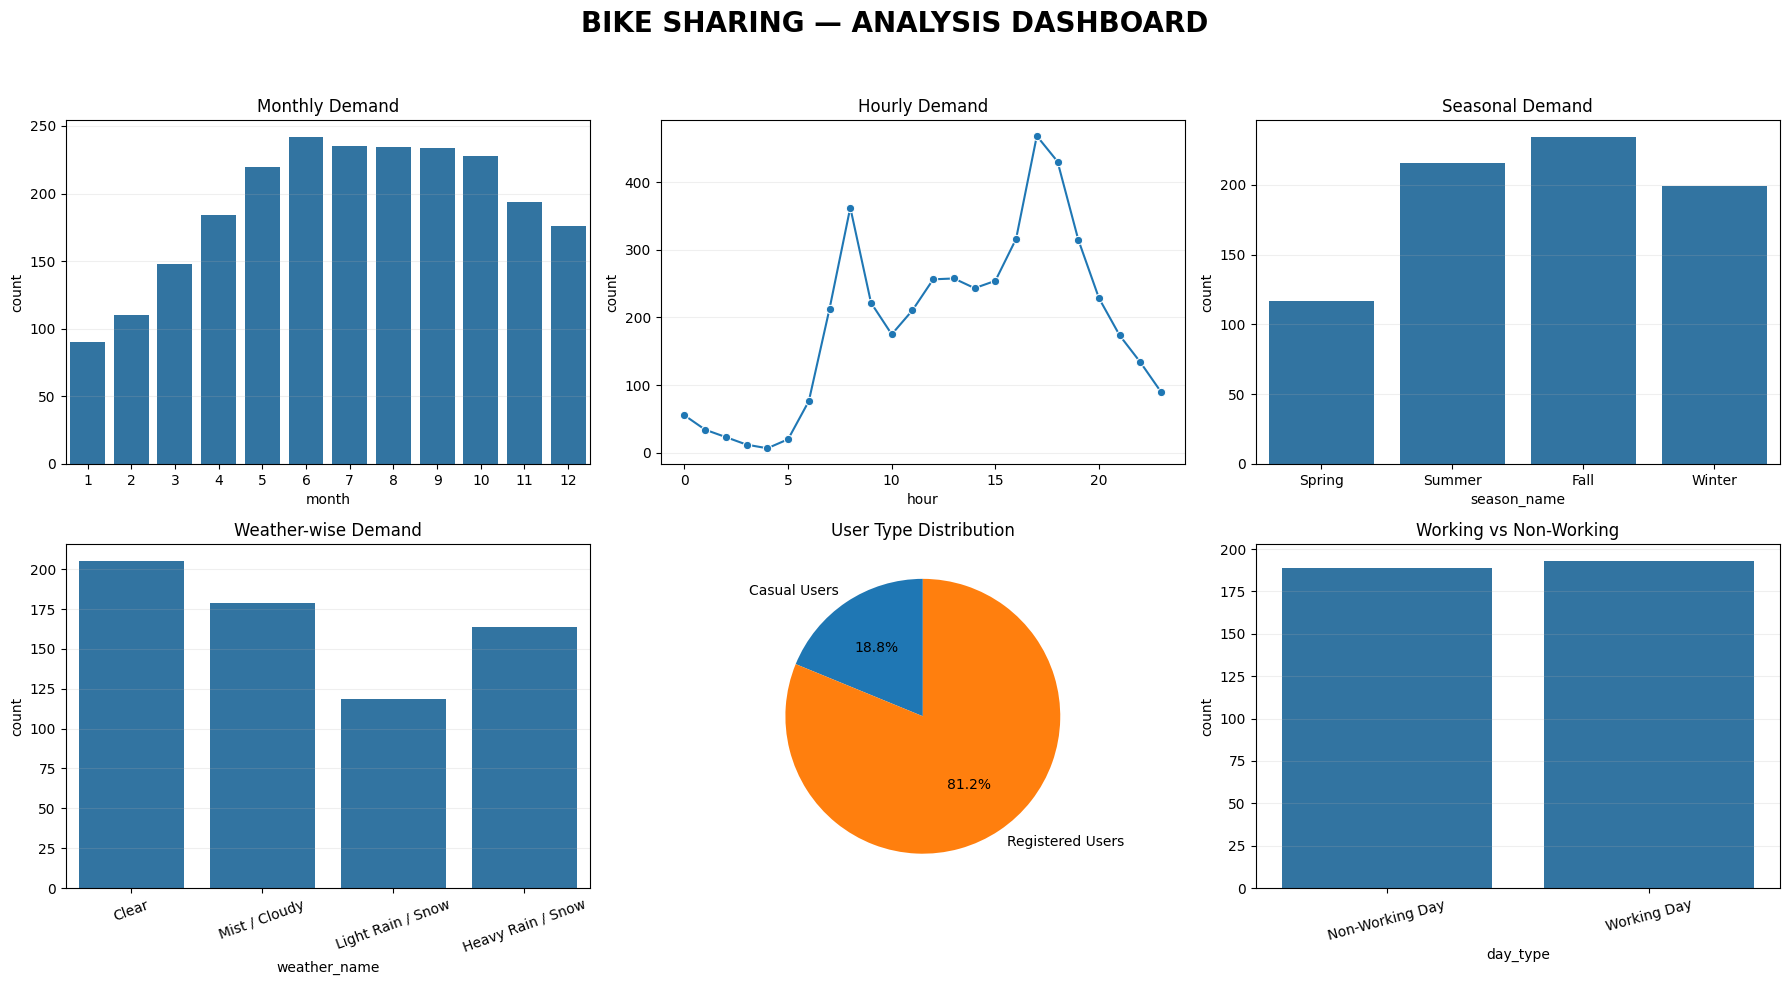

In [11]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10))

fig.suptitle(
    "BIKE SHARING — ANALYSIS DASHBOARD",
    fontsize=20,
    fontweight="bold"
)

# 1. Monthly Demand
sns.barplot(
    data=monthly_demand,
    x="month",
    y="count",
    ax=axes[0, 0]
)
axes[0, 0].set_title("Monthly Demand")

# 2. Hourly Demand
sns.lineplot(
    data=hourly_demand,
    x="hour",
    y="count",
    marker="o",
    ax=axes[0, 1]
)
axes[0, 1].set_title("Hourly Demand")

# 3. Seasonal Demand
sns.barplot(
    data=season_demand,
    x="season_name",
    y="count",
    ax=axes[0, 2]
)
axes[0, 2].set_title("Seasonal Demand")

# 4. Weather Demand
sns.barplot(
    data=weather_demand,
    x="weather_name",
    y="count",
    ax=axes[1, 0]
)
axes[1, 0].set_title("Weather-wise Demand")
axes[1, 0].tick_params(axis="x", rotation=20)

# 5. User Type
axes[1, 1].pie(
    user_type_data,
    labels=user_labels,
    autopct="%1.1f%%",
    startangle=90
)
axes[1, 1].set_title("User Type Distribution")

# 6. Working vs Non-Working
sns.barplot(
    data=working_demand,
    x="day_type",
    y="count",
    ax=axes[1, 2]
)
axes[1, 2].set_title("Working vs Non-Working")
axes[1, 2].tick_params(axis="x", rotation=15)

for ax in axes.flat:
    if ax != axes[1, 1]:
        ax.grid(axis="y", alpha=0.2)

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

In [12]:
output_file = "Bike_Sharing_Day59_Dashboard_Data.csv"

train.to_csv(output_file, index=False)

from google.colab import files
files.download(output_file)

print("Day 59 dataset saved and downloaded successfully!")
print("Dataset shape:", train.shape)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Day 59 dataset saved and downloaded successfully!
Dataset shape: (10886, 24)
